# Findelen, taken apart

This notebook builds a plate of Findelengletscher in the Valais Alps, separated into three layers: the ice surface, the ice-free rock that rises through it, and the terrain beneath the ice.

All three layers come from a single model published by Feiger et al. (2018). Surface elevation, bed elevation and ice thickness share one 25 m grid, so the layers can be compared directly.

Every layer is drawn with the same camera, which keeps the glacier outline aligned from one layer to the next. The layers differ only in their height on the page. Each one is raised just enough to clear the layer below it, so the spacing between them stays even.

Settings are kept in `scripts/anatomy_config.yaml`, and the rendering functions in `scripts/anatomy_functions.py`. Each step below ends with a small working figure of its result. These figures are for checking the process and are not part of the final plate.

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/inside-out-mpl')

import sys, json, io
from pathlib import Path
from IPython.display import Image as IPyImage, display
import yaml
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image


def find_root(start=Path.cwd()):
    """Locate the 15_inside_out folder whether we start from it, its notebooks/, or the repo root."""
    for p in [start, *start.parents]:
        if (p / 'scripts' / 'anatomy_functions.py').exists():
            return p
    raise FileNotFoundError('could not locate the 15_inside_out project root')

ROOT = find_root()
sys.path.insert(0, str(ROOT / 'scripts'))
import anatomy_functions as af

cfg = yaml.safe_load((ROOT / 'scripts' / 'anatomy_config.yaml').read_text())
view, footprint_cfg, layout, type_, colour = (cfg[k] for k in ('view', 'footprint', 'layout', 'type', 'colour'))
layer_order = tuple(layout['layer_order'])

# Use the house typeface when it is available. Söhne is licensed and kept outside Git,
# so a fresh clone falls back to DejaVu Sans, which ships with matplotlib.
fonts = cfg['fonts']
OTF_DIR = (ROOT / fonts['dir']).resolve()
font_files = sorted(OTF_DIR.glob('*.otf')) if OTF_DIR.is_dir() else []
for font in font_files:
    font_manager.fontManager.addfont(str(font))
# Read family names from matplotlib's registry; FontProperties(fname=...).get_name()
# mis-decodes the umlaut in Söhne's name table.
registered = {str(f) for f in font_files}
found = {e.name for e in font_manager.fontManager.ttflist if e.fname in registered}
title_file = OTF_DIR / fonts['title_file']

if fonts['family'] in found and title_file.exists():
    FONT_FAMILY = fonts['family']
    light_font = font_manager.FontProperties(fname=title_file)
else:
    FONT_FAMILY = fonts['fallback']
    light_font = font_manager.FontProperties(family=FONT_FAMILY)
    print(f"{fonts['family']} was not found in {OTF_DIR}, so the plate uses {FONT_FAMILY}. "
          "The layout was tuned for Söhne, so line lengths will differ slightly.")

plt.rcParams.update({
    'font.family': FONT_FAMILY, 'text.color': colour['ink'],
    'axes.titlesize': 9, 'axes.titlecolor': colour['ink'],
    'axes.labelcolor': colour['muted'], 'xtick.color': colour['muted'], 'ytick.color': colour['muted'],
})


def show(fig, dpi=100, close=True):
    """Embed a figure in the notebook output. The Agg backend does not display figures on its own."""
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, facecolor=fig.get_facecolor())
    if close:
        plt.close(fig)
    display(IPyImage(data=buf.getvalue()))


def ramp(key, reverse=False):
    """A colour ramp from the plate's materials, so working figures share its palette."""
    colours = colour['materials'][key]['ramp']
    return LinearSegmentedColormap.from_list(key, colours[::-1] if reverse else colours)


def working_figure(ncols, width=10, height=3.2, **kwargs):
    """A small figure on the plate's paper colour, used for the step-by-step checks."""
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), facecolor=colour['paper'], **kwargs)
    return fig, np.atleast_1d(axes)

## 1 · Load the elevation model

The model provides three grids at 25 m spacing: surface elevation, bed elevation and ice thickness. Cells with more than 0.1 m of ice form the glacier. Ice-free cells within the rock margin set in the configuration form the rock layer. Nunataks are the rock islands that are fully enclosed by ice.

28379 ice cells, 22638 rock cells, 15 enclosed nunataks


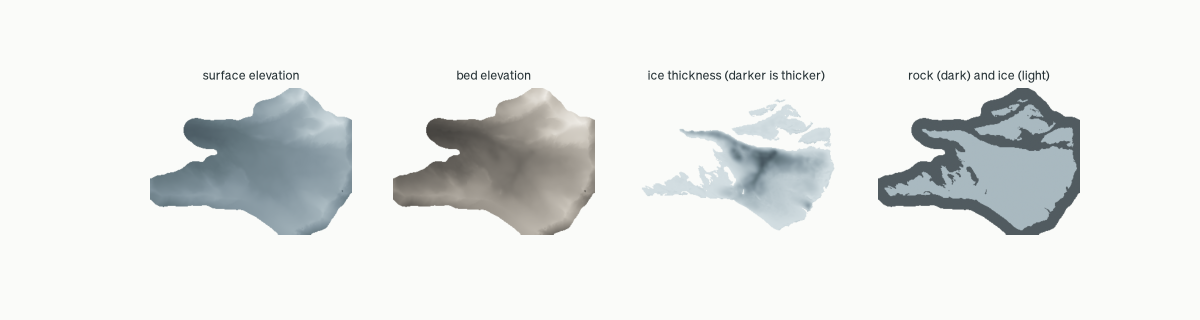

In [2]:
DATA_DIR = ROOT / cfg['paths']['data_dir']
surface, bed, thickness, cell = af.load_grids(DATA_DIR)
surface, bed, ice, footprint, thickness, rock = af.crop_to_footprint(
    surface, bed, thickness, cell, footprint_cfg['rock_margin_m'])
nunataks = af.count_nunataks(ice, footprint_cfg['nunatak_min_cells'])
print(f"{int(ice.sum())} ice cells, {int(rock.sum())} rock cells, {nunataks} enclosed nunataks")

wf, axes = working_figure(4, width=12)
panels = [
    (surface, ramp('ice'), 'surface elevation'),
    (bed, ramp('bed'), 'bed elevation'),
    (np.where(ice, thickness, np.nan), ramp('ice', reverse=True), 'ice thickness (darker is thicker)'),
]
for ax, (grid, cmap, title) in zip(axes, panels):
    ax.imshow(np.where(footprint, grid, np.nan), cmap=cmap)
    ax.set_title(title)
    ax.axis('off')
cover = np.full(ice.shape, np.nan)
cover[rock], cover[ice] = 0, 1
axes[3].imshow(cover, cmap=LinearSegmentedColormap.from_list(
    'cover', [colour['materials']['rock']['ramp'][2], colour['materials']['ice']['ramp'][3]]))
axes[3].set_title('rock (dark) and ice (light)')
axes[3].axis('off')
show(wf)

## 2 · Check that the grids agree

The three grids are published as separate files, but they should satisfy `surface = bed + thickness`. Adding the bed and thickness grids and subtracting the result from the surface tests this directly. The largest difference is about one centimetre, which is consistent with rounding in the published files.

largest |surface - (bed + thickness)| = 0.010 m across 51017 cells


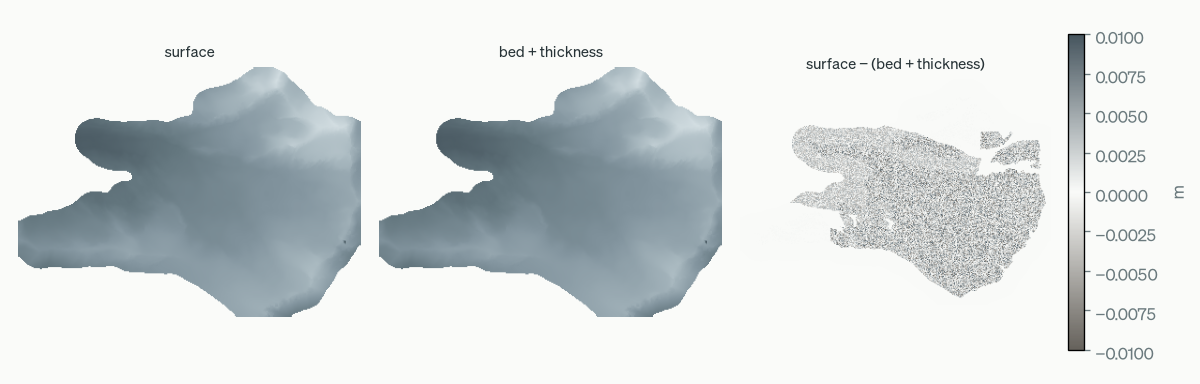

In [3]:
residual = surface - (bed + thickness)
print(f"largest |surface - (bed + thickness)| = {np.abs(residual).max():.3f} m "
      f"across {int(footprint.sum())} cells")

residual_cmap = LinearSegmentedColormap.from_list(
    'residual', [colour['materials']['bed']['ramp'][1], colour['paper'], colour['materials']['ice']['ramp'][0]])

wf, axes = working_figure(3)
for ax, grid, title in zip(axes[:2], (surface, bed + thickness), ('surface', 'bed + thickness')):
    ax.imshow(np.where(footprint, grid, np.nan), cmap=ramp('ice'))
    ax.set_title(title)
    ax.axis('off')
im = axes[2].imshow(np.where(footprint, residual, np.nan), cmap=residual_cmap, vmin=-0.01, vmax=0.01)
axes[2].set_title('surface − (bed + thickness)')
axes[2].axis('off')
wf.colorbar(im, ax=axes[2], fraction=0.046, label='m')
wf.tight_layout()
show(wf, dpi=120)

## 3 · Set up the camera

One orthographic camera is shared by all three layers. The left panel shows the direction it faces on the map. The right panel shows the surface as the camera sees it, with the vertical exaggeration applied.

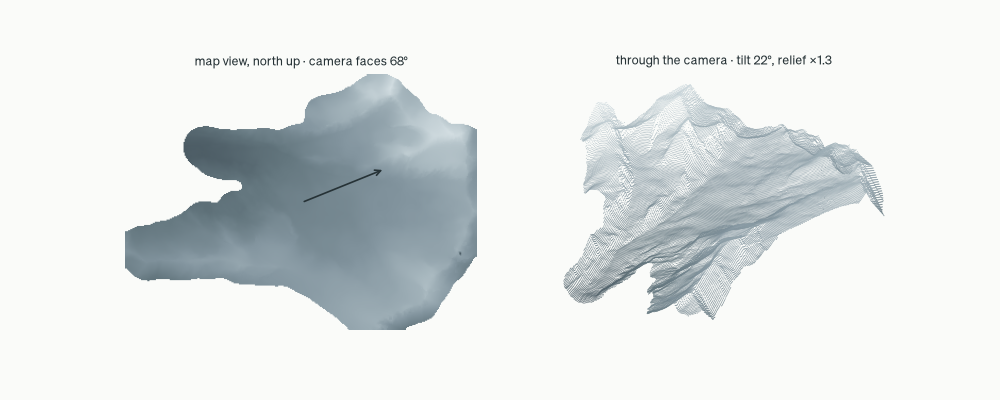

In [4]:
UP = footprint_cfg['display_resample']
sx_flat, depth_h, grid_line = af.build_camera(
    surface.shape, cell, UP, view['azimuth_deg'], view['elevation_deg'])

# The same camera at the native 25 m grid is enough to preview the view.
sx_c, depth_c, _ = af.build_camera(surface.shape, cell, 1, view['azimuth_deg'], view['elevation_deg'])
sy_c, dep_c = af.project(surface, surface.min(), view['relief'], depth_c, view['elevation_deg'])

wf, axes = working_figure(2, width=10, height=4)
axes[0].imshow(np.where(footprint, surface, np.nan), cmap=ramp('ice'))
row, col = np.array(surface.shape) / 2
arrow_len = 0.35 * min(surface.shape)
az = np.deg2rad(view['azimuth_deg'])
axes[0].annotate('', xy=(col + arrow_len * np.sin(az), row - arrow_len * np.cos(az)), xytext=(col, row),
                 arrowprops=dict(arrowstyle='->', color=colour['ink'], lw=1.2))
axes[0].set_title(f"map view, north up · camera faces {view['azimuth_deg']}°")
axes[0].axis('off')

order = np.argsort(-dep_c[footprint])                # far points first, near points on top
axes[1].scatter(sx_c[footprint][order], sy_c[footprint][order], c=surface[footprint][order],
                cmap=ramp('ice'), s=0.4, linewidths=0)
axes[1].set_aspect('equal')
axes[1].axis('off')
axes[1].set_title(f"through the camera · tilt {view['elevation_deg']}°, relief ×{view['relief']:g}")
show(wf)

## 4 · Shade and project each layer

Each layer is shaded under the same lights and projected through the same camera. Only the data and the colour ramp change from one layer to the next.

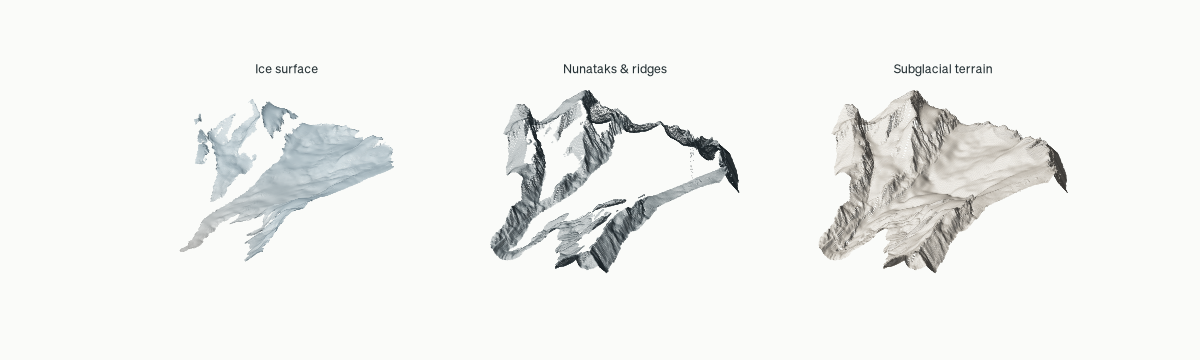

In [5]:
layer_defs = {
    'ice':  dict(z=surface, mask=ice,       label='ICE SURFACE',          sub='Glacier surface, 2016'),
    'rock': dict(z=surface, mask=rock,      label='NUNATAKS & RIDGES',    sub='Ice-free rock, 2016'),
    'bed':  dict(z=bed,     mask=footprint, label='SUBGLACIAL TERRAIN',   sub='Modelled bed, ice removed'),
}
z_ref = surface.min()
for key, L in layer_defs.items():
    L['sx'], L['sy'], L['dep'], L['rgb'] = af.render_layer(
        L['z'], L['mask'], colour['materials'][key], cell, UP, view['relief'], view['lights'],
        sx_flat, depth_h, grid_line, view['elevation_deg'], z_ref)

wf, axes = working_figure(3, width=12, height=3.6, sharex=True, sharey=True)
for ax, key in zip(axes, layer_order):
    L = layer_defs[key]
    pick = slice(None, None, 25)                      # every 25th point is enough for a preview
    order = np.argsort(-L['dep'][pick])
    ax.scatter(L['sx'][pick][order], L['sy'][pick][order], c=L['rgb'][pick][order], s=0.2, linewidths=0)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(L['label'].capitalize())
show(wf)

## 5 · Stack the layers

The outline of each layer is traced column by column across the page. Each upper layer is then raised until its lowest edge sits a fixed distance above the highest edge of the layer below. The figure shows the traced outlines after raising, with the narrowest gap between each pair marked.

gap between layers: 739 m in scene units
lift above the bottom layer: {'bed': '0 m', 'rock': '5240 m', 'ice': '10121 m'}


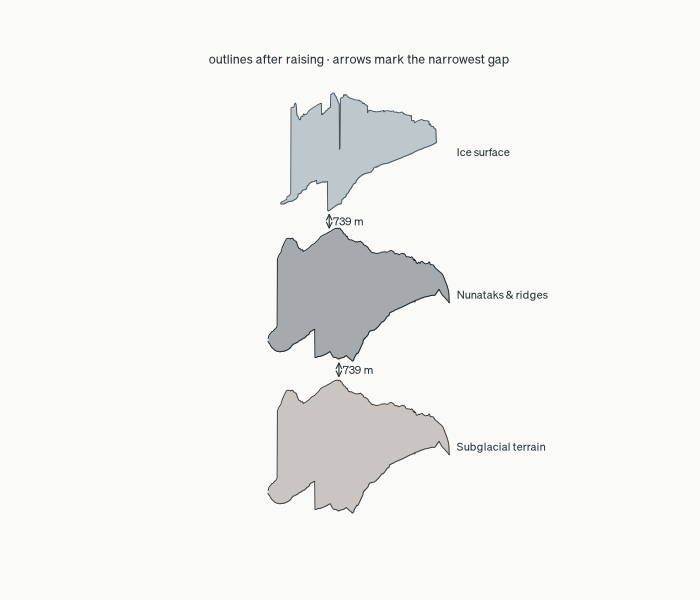

In [6]:
SX0 = min(L['sx'].min() for L in layer_defs.values())
SX1 = max(L['sx'].max() for L in layer_defs.values())
sil = {k: af.silhouette(L['sx'], L['sy'], SX0, SX1) for k, L in layer_defs.items()}
clear = af.clearance(sil, layer_order)

_, lo0, hi0 = af.stack_lifts(layer_defs, layer_order, clear, 0)
n_gaps = len(layer_order) - 1
s = (layout['stack_top'] - layout['stack_bottom'] - n_gaps * layout['layer_gap']) / (hi0 - lo0)
s = min(s, layout['plate_max_width'] * layout['fig_w_in'] / layout['fig_h_in'] / (SX1 - SX0))
lift, SY0, SY1 = af.stack_lifts(layer_defs, layer_order, clear, layout['layer_gap'] / s)

gap_m = layout['layer_gap'] / s
print(f"gap between layers: {gap_m:.0f} m in scene units")
print('lift above the bottom layer:', {k: f'{v:.0f} m' for k, v in lift.items()})

xs = np.linspace(SX0, SX1, len(sil[layer_order[0]][0]))
wf, ax = plt.subplots(figsize=(7, 6), facecolor=colour['paper'])
for key in layer_order:
    top, bot = (np.where(np.isfinite(edge), edge, np.nan) + lift[key] for edge in sil[key])
    mat = colour['materials'][key]['ramp']
    ax.fill_between(xs, bot, top, color=mat[2], alpha=.5, linewidth=0)
    ax.text(SX1 + .04 * (SX1 - SX0), (np.nanmin(bot) + np.nanmax(top)) / 2,
            layer_defs[key]['label'].capitalize(), va='center', fontsize=8)
    ax.plot(xs, top, color=mat[0], lw=.7)
    ax.plot(xs, bot, color=mat[0], lw=.7)
for upper, lower in zip(layer_order[:-1], layer_order[1:]):
    gaps = (sil[upper][1] + lift[upper]) - (sil[lower][0] + lift[lower])
    i = int(np.argmin(gaps))
    y_low, y_high = sil[lower][0][i] + lift[lower], sil[upper][1][i] + lift[upper]
    ax.annotate('', xy=(xs[i], y_high), xytext=(xs[i], y_low),
                arrowprops=dict(arrowstyle='<->', color=colour['ink'], lw=.8))
    ax.text(xs[i], (y_low + y_high) / 2, f'  {gaps[i]:.0f} m', va='center', fontsize=8)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('outlines after raising · arrows mark the narrowest gap')
show(wf)

## 6 · Combine the layers into one image

The layers are drawn from the bottom up. Where they overlap, each upper layer covers the one below it.

canvas: 1323 × 3059 px


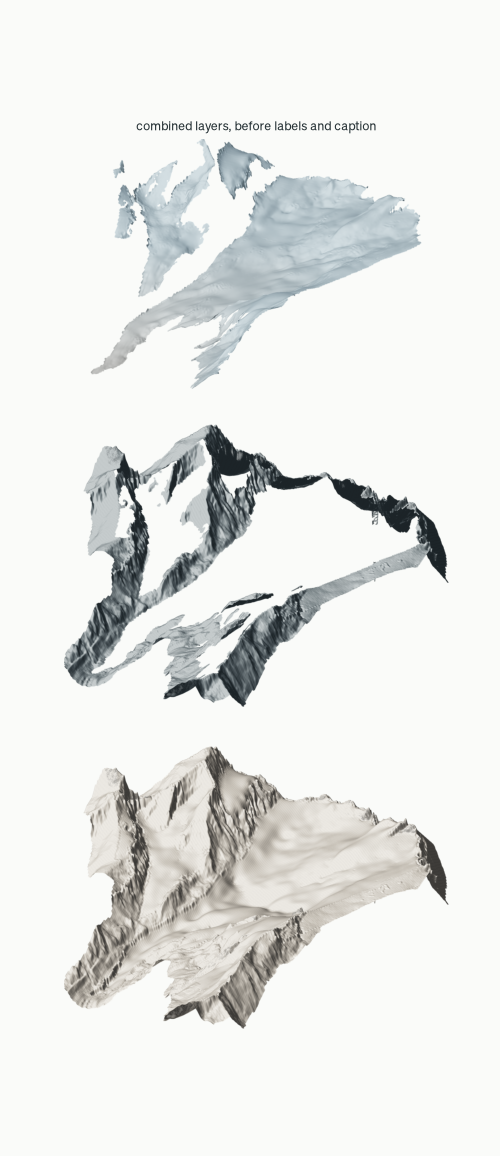

In [7]:
px_per_m = s * layout['fig_h_in'] * layout['dpi'] * layout['supersample']
Wp = int(np.ceil((SX1 - SX0) * px_per_m)) + 4
Hp = int(np.ceil((SY1 - SY0) * px_per_m)) + 4

canvas = Image.new('RGBA', (Wp, Hp), (0, 0, 0, 0))
label_anchor = {}
for key in layer_order[::-1]:
    L = layer_defs[key]
    tile = af.splat(L['sx'], L['sy'], L['dep'], L['rgb'], lift[key], SX0, SY1, px_per_m, (Wp, Hp))
    canvas = Image.alpha_composite(canvas, tile)
    label_anchor[key] = (L['sy'].min() + L['sy'].max()) / 2 + lift[key]
canvas = canvas.resize((Wp // layout['supersample'], Hp // layout['supersample']), Image.LANCZOS)

print(f"canvas: {canvas.width} × {canvas.height} px")
wf, ax = plt.subplots(figsize=(5, 5 * canvas.height / canvas.width), facecolor=colour['paper'])
ax.imshow(np.asarray(canvas))
ax.axis('off')
ax.set_title('combined layers, before labels and caption')
show(wf)

## 7 · Draw the plate

The plate is assembled in three steps: the terrain, then the layer labels, then the title and caption. A small preview follows each step.

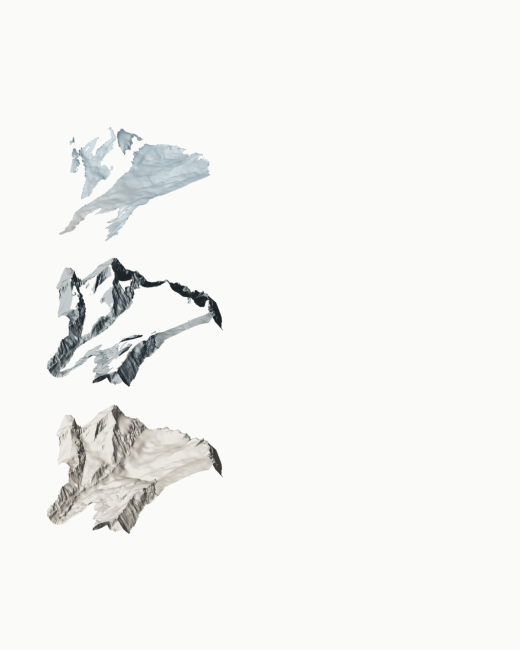

In [8]:
fig = plt.figure(figsize=(layout['fig_w_in'], layout['fig_h_in']), facecolor=colour['paper'])
plate_w = (SX1 - SX0) * s * layout['fig_h_in'] / layout['fig_w_in']
plate_h = (SY1 - SY0) * s
plate_y0 = layout['stack_bottom'] + (layout['stack_top'] - layout['stack_bottom'] - plate_h) / 2
plate_x0 = layout['plate_left'] + .02   # nudged right of the body-text margin

ax = fig.add_axes([plate_x0, plate_y0, plate_w, plate_h])
ax.imshow(np.asarray(canvas), interpolation='antialiased')
ax.axis('off')

show(fig, dpi=40, close=False)

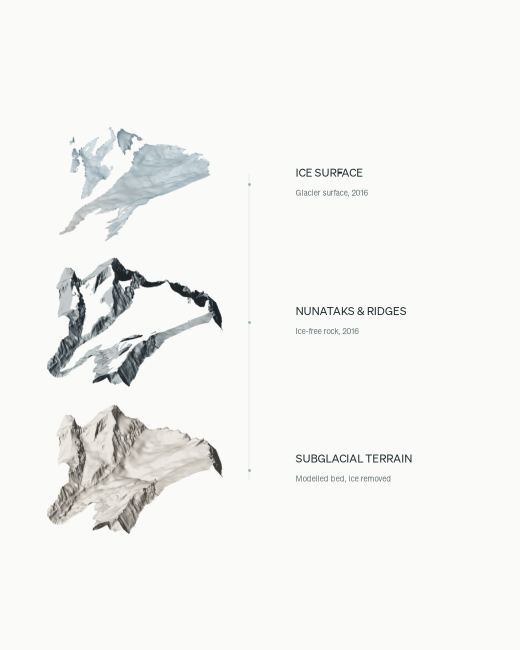

In [9]:
# Labels, dots and the connector line that reads as a shared depth axis.
label_x_dot = plate_x0 + plate_w + layout['label_gap_x']
label_x_text = label_x_dot + layout['label_text_indent']
label_ys = []
for key in layer_order:
    L = layer_defs[key]
    y = plate_y0 + (label_anchor[key] - SY0) * s
    label_ys.append(y)
    fig.text(label_x_text, y + .004, L['label'], fontsize=type_['size_label'], va='bottom')
    fig.text(label_x_text, y - .004, L['sub'], fontsize=type_['size_label_sub'], va='top', color=colour['muted'])
    fig.add_artist(plt.Line2D([label_x_dot], [y], marker='o', ms=5, color='#8fb6be',
                              mec='none', transform=fig.transFigure, zorder=5))
fig.add_artist(plt.Line2D([label_x_dot, label_x_dot], [min(label_ys) - .015, max(label_ys) + .015],
                          lw=.6, color='#c0d0d4', transform=fig.transFigure, zorder=4))

show(fig, dpi=40, close=False)

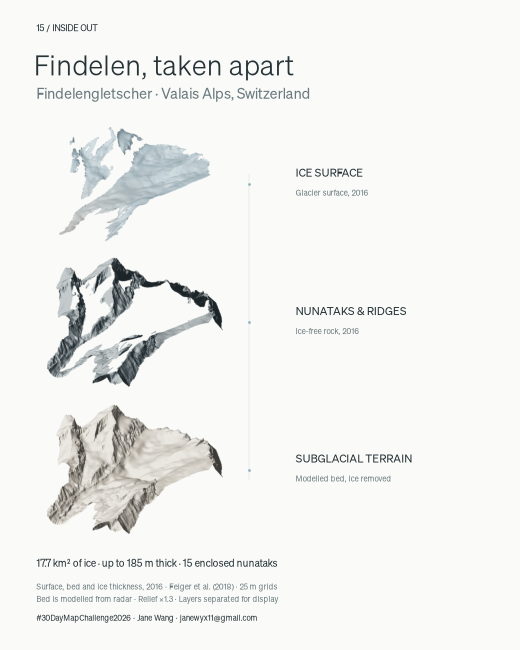

In [10]:
# Title, subtitle and the computed stats/footer.
fig.text(layout['plate_left'], .952, '15 / INSIDE OUT', fontsize=type_['size_eyebrow'])
fig.text(layout['plate_left'] - .005, .884, 'Findelen, taken apart',
         fontproperties=light_font, fontsize=type_['size_title'])
fig.text(layout['plate_left'], .848, 'Findelengletscher · Valais Alps, Switzerland',
         fontsize=type_['size_subtitle'], color=colour['muted'])

area_km2 = ice.sum() * cell ** 2 / 1e6
volume_km3 = thickness[ice].sum() * cell ** 2 / 1e9
fig.text(layout['plate_left'], .128,
         f"{area_km2:.1f} km² of ice · up to {thickness.max():.0f} m thick · {nunataks} enclosed nunataks",
         fontsize=type_['size_stats'])
fig.text(layout['plate_left'], .093,
         'Surface, bed and ice thickness, 2016 · Feiger et al. (2018) · 25 m grids',
         fontsize=type_['size_footer'], color=colour['muted'])
fig.text(layout['plate_left'], .074,
         f"Bed is modelled from radar · Relief ×{view['relief']:g} · Layers separated for display",
         fontsize=type_['size_footer'], color=colour['muted'])
fig.text(layout['plate_left'], .045, '#30DayMapChallenge2026 · Jane Wang · janewyx11@gmail.com',
         fontsize=type_['size_footer'])

show(fig, dpi=40, close=False)

## 8 · Save the plate

In [11]:
out_dir = ROOT / cfg['paths']['out_dir']
fig.savefig(out_dir / 'findelen_anatomy.png', dpi=layout['dpi'], facecolor=colour['paper'])

full = Image.open(out_dir / 'findelen_anatomy.png')
full.resize((1300, round(1300 * full.height / full.width)), Image.LANCZOS).save(
    out_dir / 'findelen_anatomy_preview.png')

meta = dict(
    source='Feiger et al. 2018, 25 m dhm/bedrock/ice_thickness fin2016',
    ice_km2=round(float(area_km2), 3), max_thickness_m=round(float(thickness.max()), 1),
    volume_km3=round(float(volume_km3), 3), enclosed_nunataks=nunataks,
    nunatak_min_cells=footprint_cfg['nunatak_min_cells'], rock_margin_m=footprint_cfg['rock_margin_m'],
    display_mesh_m=round(cell / UP, 2), relief=view['relief'],
    view_azimuth_deg=view['azimuth_deg'], view_elevation_deg=view['elevation_deg'],
    layer_order=list(layer_order))
(out_dir / 'findelen_anatomy_metadata.json').write_text(json.dumps(meta, indent=2))

379

## 9 · Preview

The saved plate is shown below, so the notebook carries the final graphic as well as the file on disk.

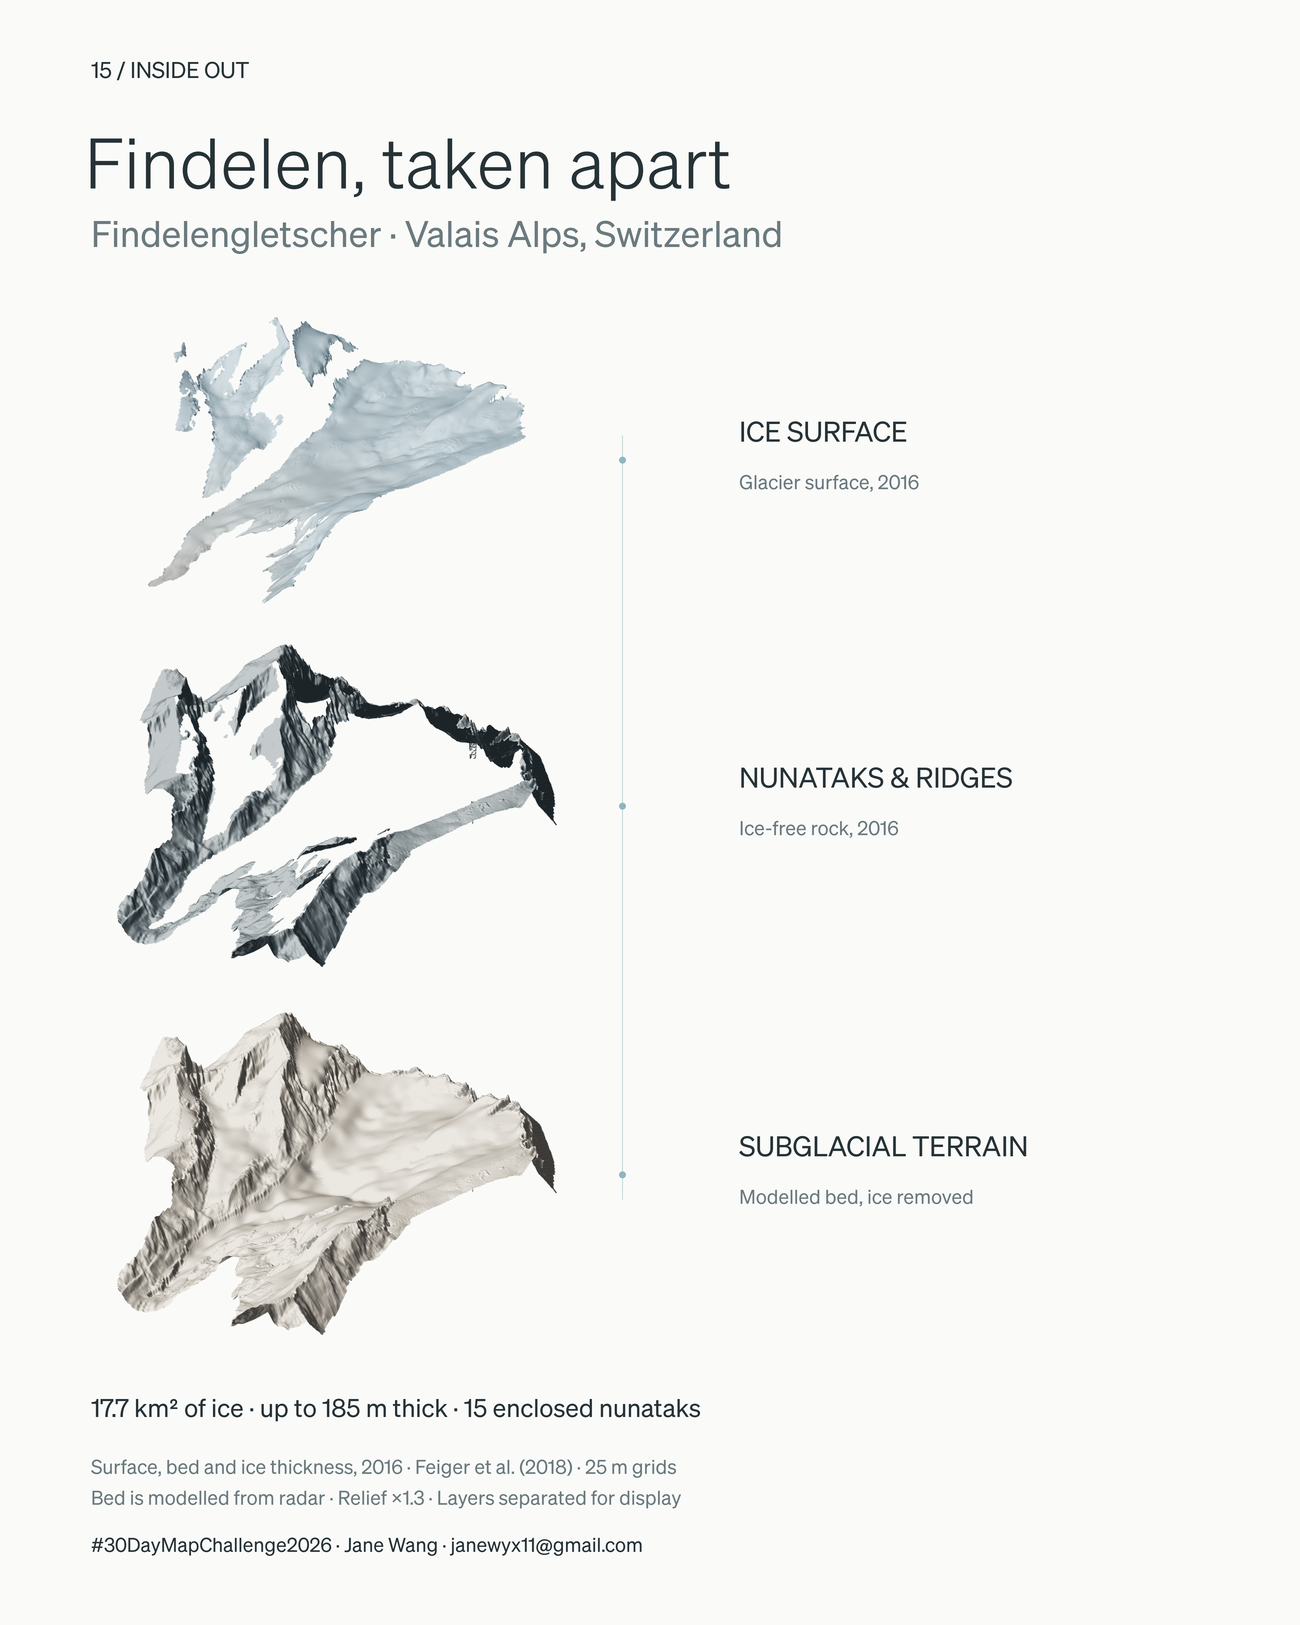

In [12]:
display(IPyImage(filename=str(out_dir / 'findelen_anatomy_preview.png')))

In [13]:
meta

{'source': 'Feiger et al. 2018, 25 m dhm/bedrock/ice_thickness fin2016',
 'ice_km2': 17.737,
 'max_thickness_m': 184.8,
 'volume_km3': 0.634,
 'enclosed_nunataks': 15,
 'nunatak_min_cells': 2,
 'rock_margin_m': 450,
 'display_mesh_m': 2.08,
 'relief': 1.3,
 'view_azimuth_deg': 68,
 'view_elevation_deg': 22,
 'layer_order': ['ice', 'rock', 'bed']}